&nbsp;

&nbsp;

## Survey: up5p divergent lncRNA pairs

&nbsp;

### BackGround

- 

&nbsp;

In [1]:
import re
import os
import pathlib
import datetime
import subprocess
import polars as pl
from IPython.display import display
from IPython.display import Image
from pygenometracks.readGtf import ReadGtf

pl.Config.set_fmt_str_lengths(200)
os.environ["POLARS_MAX_THREADS"] = "16"

In [2]:
execute_date = datetime.datetime.now().strftime("%y%m%d")  # noqa: DTZ005
print(f"Execute Date: {execute_date}")

Execute Date: 261019


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Up5p Upsetplot Intersection Result

In [3]:
up5p_intersect_result = pl.read_csv(
    "../../../out/transcript_classification/upsetplot/up5p_transcript_upset_data_v261010.tsv",
    separator="\t",
    n_threads=16
).with_columns(
    # Split "ENST...-FCHS_..." into transcript_id and cre_id
    pl.col("id")
    .str.split_exact("-", 1)
    .struct.rename_fields(["transcript_id", "cre_id"])
    .alias("id_parts")
).unnest("id_parts")


display(up5p_intersect_result)

all pairs,derived from CLS3 project,Diff Analysis (ATAC-seq),Diff Analysis (HSF1),divergent,enhancer-derived,id,transcript_id,cre_id
bool,bool,bool,bool,bool,bool,str,str,str
true,true,false,false,false,false,"""ENST00000762829.1-FCHS_442950""","""ENST00000762829.1""","""FCHS_442950"""
true,false,false,false,false,true,"""ENST00000607794.2-FCHS_149384""","""ENST00000607794.2""","""FCHS_149384"""
true,true,false,false,false,false,"""ENST00000830147.1-FCHS_318953""","""ENST00000830147.1""","""FCHS_318953"""
true,true,false,false,false,false,"""ENST00000773409.1-FCHS_199701""","""ENST00000773409.1""","""FCHS_199701"""
true,true,false,false,false,false,"""ENST00000810898.1-FCHS_17158""","""ENST00000810898.1""","""FCHS_17158"""
…,…,…,…,…,…,…,…,…
true,true,false,false,false,false,"""ENST00000772900.1-FCHS_130885""","""ENST00000772900.1""","""FCHS_130885"""
true,false,false,false,false,true,"""ENST00000423178.6-FCHS_466850""","""ENST00000423178.6""","""FCHS_466850"""
true,true,false,false,false,false,"""ENST00000783516.1-FCHS_110693""","""ENST00000783516.1""","""FCHS_110693"""


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## HSF1 regulation  + Diff-Analysis + divergent

- 最も注目できる up5p transcripts の組み合わせ

In [4]:
hsf1_divergent_lncrna = up5p_intersect_result.filter(
    (pl.col("Diff Analysis (HSF1)") == True)
    & (pl.col("divergent") == True)
    & (pl.col("Diff Analysis (ATAC-seq)") == True)
    & (pl.col("enhancer-derived") == False)
    # & (pl.col("derived from CLS3 project") == True)
)

display(hsf1_divergent_lncrna)

all pairs,derived from CLS3 project,Diff Analysis (ATAC-seq),Diff Analysis (HSF1),divergent,enhancer-derived,id,transcript_id,cre_id
bool,bool,bool,bool,bool,bool,str,str,str
true,true,true,true,true,false,"""ENST00000805843.1-FCHS_201752""","""ENST00000805843.1""","""FCHS_201752"""
true,true,true,true,true,false,"""ENST00000700791.2-FCHS_354486""","""ENST00000700791.2""","""FCHS_354486"""
true,false,true,true,true,false,"""ENST00000540428.1-FCHS_86240""","""ENST00000540428.1""","""FCHS_86240"""
true,false,true,true,true,false,"""ENST00000665702.1-FCHS_338098""","""ENST00000665702.1""","""FCHS_338098"""
true,true,true,true,true,false,"""ENST00000702650.2-FCHS_353060""","""ENST00000702650.2""","""FCHS_353060"""
…,…,…,…,…,…,…,…,…
true,true,true,true,true,false,"""ENST00000738053.1-FCHS_72810""","""ENST00000738053.1""","""FCHS_72810"""
true,true,true,true,true,false,"""ENST00000729764.1-FCHS_110516""","""ENST00000729764.1""","""FCHS_110516"""
true,true,true,true,true,false,"""ENST00000688681.2-FCHS_72810""","""ENST00000688681.2""","""FCHS_72810"""


&nbsp;

&nbsp;

## Transcript - CRE pairs

- 今回の解析で、具体的にどのような transcript - CRE pair が取得できたか確認する

In [5]:
up5p_cre_pair = pl.read_parquet(
    "../../../out/transcript_classification/divergent_transcript/pc_common_cre_lncRNA_divergent/up5p_fantabio_pc_common_cre_lncRNA_divergent.parquet"
).filter(
    # pair としてフィルタリング
    (pl.col("lncrna_transcript_id").is_in(hsf1_divergent_lncrna.get_column("transcript_id").unique().implode()))
    & (pl.col("cre_id").is_in(hsf1_divergent_lncrna.get_column("cre_id").unique().implode()))
).filter(
    pl.col("pc_lncrna_HN2") >= 300
)

print(f"up5p cre all pair: {up5p_cre_pair.select(['lncrna_transcript_id', 'cre_id']).n_unique()}")
pl.Config.set_tbl_rows(10)
display(up5p_cre_pair)

up5p cre all pair: 13


cre_id,cre_name,fantabio_cre_class,cre_chrom,cre_chrom_start,cre_chrom_end,directionality,pc_transcript_distance,screen_ccres,fantom5_enhancers,pc_transcript_id,pc_HN2,pc_transcript_strand,pc_transcript_info,lncrna_transcript_distance,lncrna_transcript_id,lncrna_HN2,lncrna_transcript_strand,lncrna_transcript_info,strand_type,pc_lncrna_HN2,id_correspondence_flag,Transcript_classification_codes,FANTOM-CAT_transcript_lv4_stringent,gene class,fantomcat_transcript_info,screen_promoter_support,ensembl_promoter_window_support,fantomcat_stringent_support
str,str,str,str,i64,i64,f64,i64,list[struct[2]],list[struct[1]],str,i64,str,struct[5],i64,str,i64,str,struct[5],str,i64,str,str,str,str,list[struct[7]],str,str,str
"""FCHS_110516""","""cp7@HSPH1""","""PLA""","""chr13""",31161745,31162676,-0.981672,0,"[{""EH38E3059049"",""pELS""}, {""EH38E3059050"",""PLS""}, … {""EH38E3059052"",""pELS""}]",null,"""ENST00000954002.1""",263,"""-""","{""ENSG00000120694.21"",""HSPH1"",""protein_coding"",null,[""basic"", ""TAGENE"", ""CCDS""]}",0,"""ENST00000729765.1""",295,"""+""","{""ENSG00000295391.1"",null,""lncRNA"",""URS0002A422B0"",[""basic"", ""TAGENE""]}","""opposite strand""",558,"""4_equal_fantom_native""","""=""","""FTMT25200000861.1""","""uncertain coding""","[{""CATG00000014230.1"",""promoter"",138.6,730.6,null,null,1.3800e-10}]","""supported by SCREEN""","""supported by Ensembl/GENCODE promoter window""","""not supported by FANTOM-CAT (stringent)"""
"""FCHS_354486""","""cp1@HSPA1A,cp1@HSPA1B""","""PLA""","""chr6""",31827058,31827936,0.997399,0,"[{""EH38E3700980"",""pELS""}, {""EH38E3700981"",""pELS""}, {""EH38E3700982"",""PLS""}]",null,"""ENST00000375650.5""",286,"""+""","{""ENSG00000204388.7"",""HSPA1B"",""protein_coding"",null,[""basic"", ""Ensembl_canonical"", … ""CCDS""]}",0,"""ENST00000700791.2""",251,"""-""","{""ENSG00000289829.2"",null,""lncRNA"",""URS0002A24591"",[""basic"", ""Ensembl_canonical"", … ""TAGENE""]}","""opposite strand""",537,null,null,null,null,null,"""supported by SCREEN""","""supported by Ensembl/GENCODE promoter window""","""not supported by FANTOM-CAT (stringent)"""
"""FCHS_201752""","""cp2@DNAJB1""","""PLA""","""chr19""",14517660,14518356,-0.988761,0,"[{""EH38E3292871"",""PLS""}, {""EH38E3292872"",""PLS""}, {""EH38E3292873"",""PLS""}]",null,"""ENST00000677204.1""",304,"""-""","{""ENSG00000132002.10"",""DNAJB1"",""protein_coding"",null,[""alternative_5_UTR"", ""CAGE_supported_TSS"", … ""CCDS""]}",242,"""ENST00000805843.1""",221,"""+""","{""ENSG00000304733.1"",null,""lncRNA"",""URS0002A4CD18"",[""basic"", ""Ensembl_canonical"", … ""TAGENE""]}","""opposite strand""",525,null,null,null,null,null,"""supported by SCREEN""","""not supported by Ensembl/GENCODE promoter window""","""not supported by FANTOM-CAT (stringent)"""
"""FCHS_110516""","""cp7@HSPH1""","""PLA""","""chr13""",31161745,31162676,-0.981672,0,"[{""EH38E3059049"",""pELS""}, {""EH38E3059050"",""PLS""}, … {""EH38E3059052"",""pELS""}]",null,"""ENST00000380405.7""",226,"""-""","{""ENSG00000120694.21"",""HSPH1"",""protein_coding"",null,[""basic"", ""GENCODE_Primary"", … ""CCDS""]}",0,"""ENST00000729765.1""",295,"""+""","{""ENSG00000295391.1"",null,""lncRNA"",""URS0002A422B0"",[""basic"", ""TAGENE""]}","""opposite strand""",521,"""4_equal_fantom_native""","""=""","""FTMT25200000861.1""","""uncertain coding""","[{""CATG00000014230.1"",""promoter"",138.6,730.6,null,null,1.3800e-10}]","""supported by SCREEN""","""supported by Ensembl/GENCODE promoter window""","""not supported by FANTOM-CAT (stringent)"""
"""FCHS_201752""","""cp2@DNAJB1""","""PLA""","""chr19""",14517660,14518356,-0.988761,0,"[{""EH38E3292871"",""PLS""}, {""EH38E3292872"",""PLS""}, {""EH38E3292873"",""PLS""}]",null,"""ENST00000598235.2""",299,"""-""","{""ENSG00000132002.10"",""DNAJB1"",""protein_coding"",null,[""alternative_5_UTR"", ""CAGE_supported_TSS"", … ""CCDS""]}",242,"""ENST00000805843.1""",221,"""+""","{""ENSG00000304733.1"",null,""lncRNA"",""URS0002A4CD18"",[""basic"", ""Ensembl_canonical"", …

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 3. Representative protein-coding transcript - CRE - lncRNA transcript

- HN-score が、protein-coding transcript + lncRNA transcript で最も高い FCHS_110516 を選抜する

In [6]:
FCHS_110516_pair = up5p_cre_pair.filter(
    pl.col("cre_id") == "FCHS_110516"
)


pl.Config.set_tbl_rows(15)
display(FCHS_110516_pair)

cre_id,cre_name,fantabio_cre_class,cre_chrom,cre_chrom_start,cre_chrom_end,directionality,pc_transcript_distance,screen_ccres,fantom5_enhancers,pc_transcript_id,pc_HN2,pc_transcript_strand,pc_transcript_info,lncrna_transcript_distance,lncrna_transcript_id,lncrna_HN2,lncrna_transcript_strand,lncrna_transcript_info,strand_type,pc_lncrna_HN2,id_correspondence_flag,Transcript_classification_codes,FANTOM-CAT_transcript_lv4_stringent,gene class,fantomcat_transcript_info,screen_promoter_support,ensembl_promoter_window_support,fantomcat_stringent_support
str,str,str,str,i64,i64,f64,i64,list[struct[2]],list[struct[1]],str,i64,str,struct[5],i64,str,i64,str,struct[5],str,i64,str,str,str,str,list[struct[7]],str,str,str
"""FCHS_110516""","""cp7@HSPH1""","""PLA""","""chr13""",31161745,31162676,-0.981672,0,"[{""EH38E3059049"",""pELS""}, {""EH38E3059050"",""PLS""}, … {""EH38E3059052"",""pELS""}]",null,"""ENST00000954002.1""",263,"""-""","{""ENSG00000120694.21"",""HSPH1"",""protein_coding"",null,[""basic"", ""TAGENE"", ""CCDS""]}",0,"""ENST00000729765.1""",295,"""+""","{""ENSG00000295391.1"",null,""lncRNA"",""URS0002A422B0"",[""basic"", ""TAGENE""]}","""opposite strand""",558,"""4_equal_fantom_native""","""=""","""FTMT25200000861.1""","""uncertain coding""","[{""CATG00000014230.1"",""promoter"",138.6,730.6,null,null,1.3800e-10}]","""supported by SCREEN""","""supported by Ensembl/GENCODE promoter window""","""not supported by FANTOM-CAT (stringent)"""
"""FCHS_110516""","""cp7@HSPH1""","""PLA""","""chr13""",31161745,31162676,-0.981672,0,"[{""EH38E3059049"",""pELS""}, {""EH38E3059050"",""PLS""}, … {""EH38E3059052"",""pELS""}]",null,"""ENST00000380405.7""",226,"""-""","{""ENSG00000120694.21"",""HSPH1"",""protein_coding"",null,[""basic"", ""GENCODE_Primary"", … ""CCDS""]}",0,"""ENST00000729765.1""",295,"""+""","{""ENSG00000295391.1"",null,""lncRNA"",""URS0002A422B0"",[""basic"", ""TAGENE""]}","""opposite strand""",521,"""4_equal_fantom_native""","""=""","""FTMT25200000861.1""","""uncertain coding""","[{""CATG00000014230.1"",""promoter"",138.6,730.6,null,null,1.3800e-10}]","""supported by SCREEN""","""supported by Ensembl/GENCODE promoter window""","""not supported by FANTOM-CAT (stringent)"""
"""FCHS_110516""","""cp7@HSPH1""","""PLA""","""chr13""",31161745,31162676,-0.981672,0,"[{""EH38E3059049"",""pELS""}, {""EH38E3059050"",""PLS""}, … {""EH38E3059052"",""pELS""}]",null,"""ENST00000936551.1""",221,"""-""","{""ENSG00000120694.21"",""HSPH1"",""protein_coding"",null,[""basic"", ""TAGENE""]}",0,"""ENST00000729765.1""",295,"""+""","{""ENSG00000295391.1"",null,""lncRNA"",""URS0002A422B0"",[""basic"", ""TAGENE""]}","""opposite strand""",516,"""4_equal_fantom_native""","""=""","""FTMT25200000861.1""","""uncertain coding""","[{""CATG00000014230.1"",""promoter"",138.6,730.6,null,null,1.3800e-10}]","""supported by SCREEN""","""supported by Ensembl/GENCODE promoter window""","""not supported by FANTOM-CAT (stringent)"""
"""FCHS_110516""","""cp7@HSPH1""","""PLA""","""chr13""",31161745,31162676,-0.981672,0,"[{""EH38E3059049"",""pELS""}, {""EH38E3059050"",""PLS""}, … {""EH38E3059052"",""pELS""}]",null,"""ENST00000853999.1""",195,"""-""","{""ENSG00000120694.21"",""HSPH1"",""protein_coding"",null,[""basic"", ""TAGENE"", … ""CCDS""]}",0,"""ENST00000729765.1""",295,"""+""","{""ENSG00000295391.1"",null,""lncRNA"",""URS0002A422B0"",[""basic"", ""TAGENE""]}","""opposite strand""",490,"""4_equal_fantom_native""","""=""","""FTMT25200000861.1""","""uncertain coding""","[{""CATG00000014230.1"",""promoter"",138.6,730.6,null,null,1.3800e-10}]","""supported by SCREEN""","""supported by Ensembl/GENCODE promoter window""","""not supported by FANTOM-CAT (stringent)"""
"""FCHS_110516""","""cp7@HSPH1""","""PLA""","""chr13""",31161745,31162676,-0.981672,0,"[{""EH38E3059049"",""pELS""}, {""EH38E3059050"",""PLS""}, … {""EH38E3059052"",""pELS""}]",null,"""ENST00000954006.1""",155,"""-""","{""ENSG00000120694.21"",""HSPH1"",""protein_coding"",null,[""basic"", ""TAGENE""]}",0,"""ENST0000

In [7]:
FCHS_110516_pair_simple = FCHS_110516_pair.select(
    "cre_id", "pc_transcript_id", "lncrna_transcript_id", "pc_lncrna_HN2"
).unique(subset=["cre_id", "pc_transcript_id", "lncrna_transcript_id"], maintain_order=True)

pl.Config.set_tbl_rows(15)
display(FCHS_110516_pair_simple)

cre_id,pc_transcript_id,lncrna_transcript_id,pc_lncrna_HN2
str,str,str,i64
"""FCHS_110516""","""ENST00000954002.1""","""ENST00000729765.1""",558
"""FCHS_110516""","""ENST00000380405.7""","""ENST00000729765.1""",521
"""FCHS_110516""","""ENST00000936551.1""","""ENST00000729765.1""",516
"""FCHS_110516""","""ENST00000853999.1""","""ENST00000729765.1""",490
"""FCHS_110516""","""ENST00000954006.1""","""ENST00000729765.1""",450
"""FCHS_110516""","""ENST00000320027.10""","""ENST00000729765.1""",430
"""FCHS_110516""","""ENST00000954002.1""","""ENST00000729764.1""",408
"""FCHS_110516""","""ENST00000380405.7""","""ENST00000729764.1""",371
"""FCHS_110516""","""ENST00000954005.1""","""ENST00000729765.1""",369


&nbsp;

&nbsp;

&nbsp;

## Visualization

### 表示領域

- UCSC Genome Browser で決めた window をそのまま使う
- [UCSC Genome Browser Result](https://genome.ucsc.edu/cgi-bin/hgTracks?db=hg38&lastVirtModeType=default&lastVirtModeExtraState=&virtModeType=default&virtMode=0&nonVirtPosition=&position=chr13%3A31160114%2D31164307&hgsid=4210912167_7cCG6XFXwU2srMCWJklVkwdTnADj)
- Region: chr13:31,160,114-31,164,307

&nbsp;

### Related Dataframe

1. `FCHS_110516_pair_simple`（FCHS_110516 / cp7@HSPH1 を共有する HSPH1 の protein-coding transcript と、対向する lncRNA `ENST00000729765.1` と `ENST00000729764.1`。lncRNA の gene symbol は未付与なので `ENSG00000295391.1`）


In [8]:
# Plot window chosen on the UCSC Genome Browser (hg38).
# https://genome.ucsc.edu/cgi-bin/hgTracks?db=hg38&position=chr13%3A31160114-31164307

REGION_CHROM = "chr13"
REGION_START = 31_160_114
REGION_END = 31_164_307

repo_root = pathlib.Path("../../../").resolve()
gtf_full = repo_root / "Data/Database/GENCODE_v49/gencode.v49.chr_patch_hapl_scaff.annotation.gtf"
cre_full = repo_root / "Data/Database/fantabio/human-CREv1.2.1.hg38.cre-peaks.bed"
out_dir = (
    repo_root
    / "out/transcript_survey/pygenometracks"
    / f"FCHS_110516_{REGION_CHROM}_{REGION_START}_{REGION_END}"
)
out_dir.mkdir(parents=True, exist_ok=True)

print(out_dir)

/workspaces/HS_human_ncRNA/out/transcript_survey/pygenometracks/FCHS_110516_chr13_31160114_31164307


In [9]:
# Shared CRE for the divergent pairs in FCHS_110516_pair_simple.
# fanta.bio BED has 11 columns; pyGenomeTracks reads itemRgb only up to BED9.
# Column 4 is replaced by cre_name (e.g. cp7@HSPH1) so the label shows the gene.
cre_ids = FCHS_110516_pair_simple.select("cre_id").unique(maintain_order=True)

cre_keep = pl.read_csv(
    cre_full,
    separator="\t",
    has_header=False,
    new_columns=[
        "chrom", "start", "end", "cre_id", "score", "strand",
        "thick_start", "thick_end", "item_rgb", "cre_name", "annot",
    ],
).join(cre_ids, on="cre_id", how="inner")

cre_bed9 = out_dir / "FCHS_110516_cre.bed9.bed"
cre_keep.select(
    "chrom", "start", "end", "cre_name", "score", "strand",
    "thick_start", "thick_end", "item_rgb",
).write_csv(cre_bed9, separator="\t", include_header=False)

print(f"CRE intervals: {cre_keep.height}")
display(cre_keep.select("cre_id", "cre_name", "chrom", "start", "end"))

CRE intervals: 1


cre_id,cre_name,chrom,start,end
str,str,str,i64,i64
"""FCHS_110516""","""cp7@HSPH1""","""chr13""",31161744,31162676


In [10]:
# Transcript models for the protein-coding and lncRNA ids in FCHS_110516_pair_simple.
# A gtf track has one color, so convert to BED12 and color only by strand.
# Use the gene symbol when it exists, otherwise the Ensembl gene id.
pc_labels = FCHS_110516_pair.select(
    pl.col("pc_transcript_id").alias("transcript_id"),
    pl.when(pl.col("pc_transcript_info").struct.field("gene_symbol").is_not_null())
    .then(pl.col("pc_transcript_info").struct.field("gene_symbol"))
    .otherwise(pl.col("pc_transcript_info").struct.field("gene_id"))
    .alias("group"),
).unique(subset="transcript_id", maintain_order=True)
lnc_labels = FCHS_110516_pair.select(
    pl.col("lncrna_transcript_id").alias("transcript_id"),
    pl.when(pl.col("lncrna_transcript_info").struct.field("gene_symbol").is_not_null())
    .then(pl.col("lncrna_transcript_info").struct.field("gene_symbol"))
    .otherwise(pl.col("lncrna_transcript_info").struct.field("gene_id"))
    .alias("group"),
).unique(subset="transcript_id", maintain_order=True)
# Protein-coding transcripts first, then the divergent lncRNAs.
wanted = pl.concat(
    [
        FCHS_110516_pair_simple.select(pl.col("pc_transcript_id").alias("transcript_id")),
        FCHS_110516_pair_simple.select(pl.col("lncrna_transcript_id").alias("transcript_id")),
    ]
).unique(maintain_order=True)
tx_info = wanted.join(
    pl.concat([pc_labels, lnc_labels]).unique(subset="transcript_id", maintain_order=True),
    on="transcript_id",
    how="left",
)

# Plus strand in blue, minus strand in orange.
STRAND_RGB = {
    "+": "0,114,178",
    "-": "230,120,0",
}
tx_group = dict(zip(tx_info["transcript_id"], tx_info["group"]))

# BED12 blocks must span the whole transcript, so pull full models from the GTF.
gtf_header = subprocess.run(
    ["grep", "^#", str(gtf_full)],
    check=True,
    capture_output=True,
    text=True,
)
tx_gtf_full = out_dir / "FCHS_110516_transcripts.full.gtf"
tx_patterns = "".join(f'transcript_id "{tx_id}";\n' for tx_id in sorted(tx_group))
tx_full_hits = subprocess.run(
    ["grep", "-F", "-f", "-", str(gtf_full)],
    input=tx_patterns,
    check=True,
    capture_output=True,
    text=True,
)
tx_gtf_full.write_text(gtf_header.stdout + tx_full_hits.stdout)

tx_bed12 = out_dir / "FCHS_110516_transcripts.bed12.bed"
tx_found = set()
with tx_bed12.open("w") as handle_out:
    for tx in ReadGtf(str(tx_gtf_full), prefered_name="transcript_id", merge_transcripts=False):
        group = tx_group[tx.name]
        tx_found.add(tx.name)
        # Keep the gene name on every transcript so the HSPH1 isoforms stay readable.
        label = tx.name if group == tx.name else f"{tx.name} ({group})"
        handle_out.write(
            "\t".join(
                map(
                    str,
                    [
                        tx.chromosome, tx.start, tx.end, label, tx.score, tx.strand,
                        tx.thick_start, tx.thick_end, STRAND_RGB[tx.strand], tx.block_count,
                        ",".join(map(str, tx.block_sizes)),
                        ",".join(map(str, tx.block_starts)),
                    ],
                )
            )
            + "\n"
        )

print(f"transcripts in dataframe: {len(tx_group)}, written to BED12: {len(tx_found)}")
display(tx_info)

transcripts in dataframe: 10, written to BED12: 10


transcript_id,group
str,str
"""ENST00000954002.1""","""HSPH1"""
"""ENST00000380405.7""","""HSPH1"""
"""ENST00000936551.1""","""HSPH1"""
"""ENST00000853999.1""","""HSPH1"""
"""ENST00000954006.1""","""HSPH1"""
"""ENST00000320027.10""","""HSPH1"""
"""ENST00000954005.1""","""HSPH1"""
"""ENST00000630972.2""","""HSPH1"""
"""ENST00000729765.1""","""ENSG00000295391.1"""


INFO:pygenometracks.tracksClass:initialize 1. [spacer]
INFO:pygenometracks.tracksClass:initialize 2. [x-axis]
INFO:pygenometracks.tracksClass:initialize 3. [spacer]
INFO:pygenometracks.tracksClass:initialize 4. [fanta CRE]
100%|██████████| 1/1 [00:00<00:00, 12633.45it/s]
INFO:pygenometracks.tracksClass:initialize 5. [spacer]
INFO:pygenometracks.tracksClass:initialize 6. [transcripts]
100%|██████████| 10/10 [00:00<00:00, 55775.32it/s]
INFO:pygenometracks.tracksClass:time initializing track(s):
INFO:pygenometracks.tracksClass:0.005140066146850586
DEBUG:pygenometracks.tracksClass:Figure size in cm is 30.0 x 12.074468085106384. Dpi is set to 150

INFO:pygenometracks.tracksClass:plotting 1. [spacer]
INFO:pygenometracks.tracksClass:plotting 2. [x-axis]
INFO:pygenometracks.tracksClass:plotting 3. [spacer]
INFO:pygenometracks.tracksClass:plotting 4. [fanta CRE]
DEBUG:pygenometracks.tracks.GenomeTrack:ylim 1.08,-0.08
DEBUG:pygenometracks.tracks.GenomeTrack:ylim (np.float64(2.08), np.float64(-0.

DEBUG:pygenometracks.tracks.GenomeTrack:ylim 15.48,-0.08
DEBUG:pygenometracks.tracks.GenomeTrack:ylim (np.float64(15.48), np.float64(-0.08))


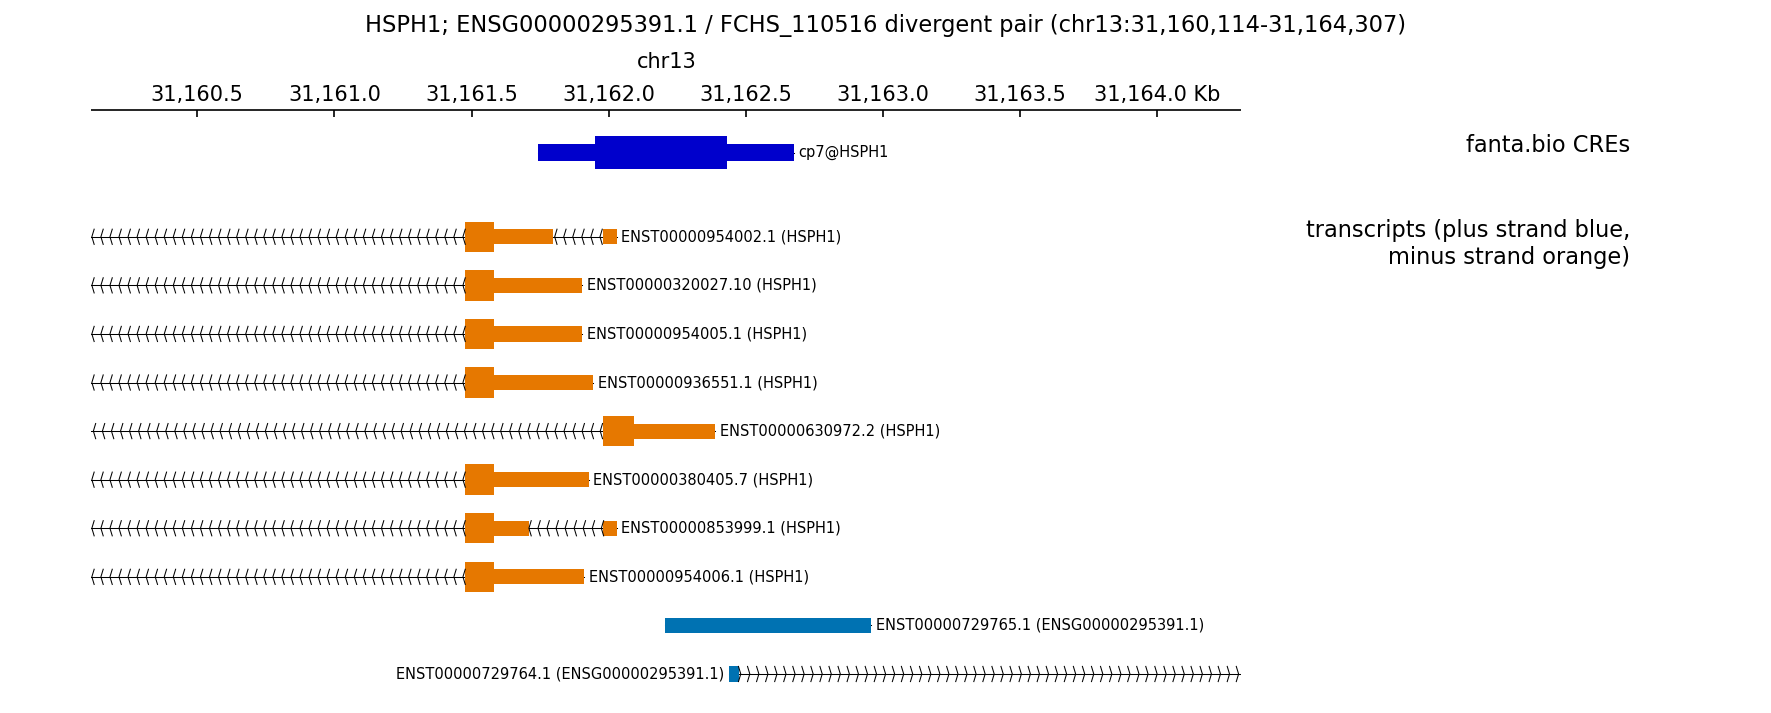

In [11]:
# CRE in the middle, transcript models at the bottom. This notebook has no ENCODE-rE2G arcs.
tracks_ini = out_dir / "FCHS_110516_tracks.ini"
figure_png = out_dir / "FCHS_110516_divergent.png"
gene_labels = tx_info.select("group").unique(maintain_order=True).to_series().to_list()
figure_title = (
    f"{'; '.join(gene_labels)} / FCHS_110516 divergent pair "
    f"({REGION_CHROM}:{REGION_START:,}-{REGION_END:,})"
)
tracks_ini.write_text(
    f"""\
[spacer]
height = 0.5

[x-axis]
where = top
fontsize = 10

[spacer]
height = 0.15

[fanta CRE]
file = {cre_bed9.name}
title = fanta.bio CREs
file_type = bed
height = 1.2
color = bed_rgb
border_color = none
labels = true
fontsize = 7
style = UCSC
display = interleaved

[spacer]
height = 0.25

[transcripts]
file = {tx_bed12.name}
title = transcripts (plus strand blue, minus strand orange)
file_type = bed
height = 8
color = bed_rgb
labels = true
all_labels_inside = true
fontsize = 7
style = UCSC
display = stacked
"""
)

# Mathtext draws digits with mathtext.rm, so both rm and it must be italic
# for gene symbols in the title to render fully italic.
mplrc = out_dir / "matplotlibrc"
mplrc.write_text(
    "mathtext.fontset : custom\n"
    "mathtext.rm : DejaVu Sans:italic\n"
    "mathtext.it : DejaVu Sans:italic\n"
)

# Stacked rows are spaced by BedTrack.row_scale, which is fixed at 2.3
# (the gene body is 1). A smaller value tightens only the gap.
# Patch it in a fresh process so the notebook kernel is left unchanged.
plot_code = """
from pygenometracks.tracks.BedTrack import BedTrack
from pygenometracks.plotTracks import main
import sys

_orig_bed_init = BedTrack.__init__

def _bed_init(self, *args, **kwargs):
    _orig_bed_init(self, *args, **kwargs)
    if self.properties.get("section_name", "").endswith("[transcripts]"):
        self.row_scale = 1.6

BedTrack.__init__ = _bed_init
main(sys.argv[1:])
"""
subprocess.run(
    [
        "python3",
        "-c",
        plot_code,
        "--tracks",
        str(tracks_ini),
        "--region",
        f"{REGION_CHROM}:{REGION_START}-{REGION_END}",
        "--width",
        "30",
        "--dpi",
        "150",
        "--trackLabelFraction",
        "0.25",
        "--trackLabelHAlign",
        "right",
        "--outFileName",
        str(figure_png),
        "--title",
        figure_title,
    ],
    check=True,
    cwd=out_dir,
    env={**os.environ, "MATPLOTLIBRC": str(mplrc)},
)
display(Image(filename=str(figure_png)))
